# MobileNetV2 vs MobileViT-XS on PlantVillage
Accuracy vs deployability of a lightweight CNN and a hybrid CNN-ViT for plant disease classification.

## Setup

In [1]:
BRANCH = "feature/training"
DRIVE_DIR = "/content/drive/MyDrive/cnn-vit-research"
RUN_ABLATION = True
RUN_ROBUSTNESS = True
SMOKE = False  # tiny synthetic dataset, only for testing the pipeline

In [2]:
import os, subprocess, sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    REPO = "/content/cnn-vit-research-"
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", "-b", BRANCH,
                        "https://github.com/SilverUmer21/cnn-vit-research-.git", REPO], check=True)
    else:
        subprocess.run(["git", "-C", REPO, "pull", "-q", "origin", BRANCH], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers>=4.40", "scikit-learn", "scipy"], check=True)
else:
    REPO = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(REPO)
sys.path.insert(0, REPO)

Mounted at /content/drive


In [3]:
import torch, transformers

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| transformers", transformers.__version__)
print("device:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "cpu")

torch 2.14.1+cu130 | transformers 5.22.1
device: Tesla T4


## Data

In [4]:
import glob, shutil, zipfile
from pathlib import Path

def find_data_root(base):
    for p in sorted(Path(base).rglob("train")):
        if p.is_dir() and (p.parent / "val").is_dir():
            return p.parent
    return None

if SMOKE:
    from src.experiments.smoke import make_smoke_data
    LOCAL = Path("/content/smoke" if IN_COLAB else "/tmp/plantvillage_smoke")
    make_smoke_data("splits/manifest.csv", LOCAL / "PlantVillage", LOCAL / "manifest.csv")
    DATA_ROOT, MANIFEST, PERSIST = LOCAL / "PlantVillage", LOCAL / "manifest.csv", LOCAL / "persist"
else:
    # reading 54k small files from Drive is slow, so unzip to the local disk once per session
    LOCAL = Path("/content/data")
    DATA_ROOT = find_data_root(LOCAL) if LOCAL.exists() else None
    if DATA_ROOT is None:
        zips = sorted(glob.glob(f"{DRIVE_DIR}/data/*.zip"))
        assert zips, f"no zip found in {DRIVE_DIR}/data/"
        LOCAL.mkdir(parents=True, exist_ok=True)
        shutil.copy(zips[0], "/content/plantvillage.zip")
        zipfile.ZipFile("/content/plantvillage.zip").extractall(LOCAL)
        os.remove("/content/plantvillage.zip")
        DATA_ROOT = find_data_root(LOCAL)
    MANIFEST, PERSIST = Path(REPO) / "splits/manifest.csv", Path(DRIVE_DIR)
print("data root:", DATA_ROOT)

data root: /content/data/PlantVillage


In [5]:
import pandas as pd
from src.experiments.config import (Paths, TrainConfig, BenchmarkConfig, SEEDS, MODELS, MODEL_ORDER,
                                    main_runs, ablation_runs, run_name)

paths = Paths(repo=REPO, persist=PERSIST, data_root=DATA_ROOT, manifest=MANIFEST).make()
manifest = pd.read_csv(paths.manifest)
missing = [p for p in manifest["path"] if not (paths.data_root / p).exists()]
assert not missing, f"{len(missing)} images missing, e.g. {missing[:3]}"
print(f"{len(manifest):,} images found")

CFG = TrainConfig()
if SMOKE:
    CFG = CFG.with_overrides(epochs=2, batch_size=16, eval_batch_size=32, lr=1e-3)
SEED_LIST = SEEDS if not SMOKE else (42,)
CFG

54,304 images found


TrainConfig(epochs=10, batch_size=32, lr=0.0001, weight_decay=0.0001, patience=5, min_delta=0.0, scheduler='cosine_per_step', amp=True, eval_batch_size=128, num_workers=2, prefetch_factor=4, label_smoothing=0.0, grad_clip_norm=None, max_train_batches=None, max_eval_batches=None)

## 1. Data preparation
Fixed split from `splits/manifest.csv`: 80/10/10, stratified by class, with duplicate and near-duplicate
images kept in the same split.

       images  groups
split                
train   43442   43359
val      5431    5421
test     5431    5420
groups in more than one split: 0


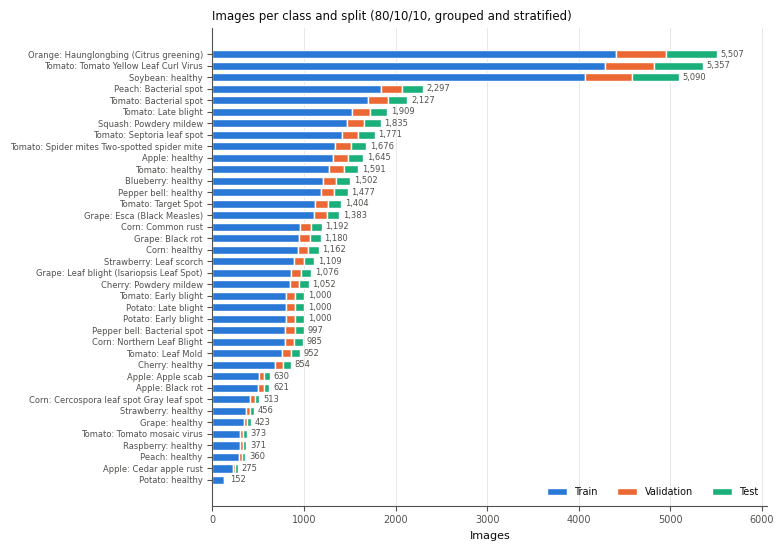

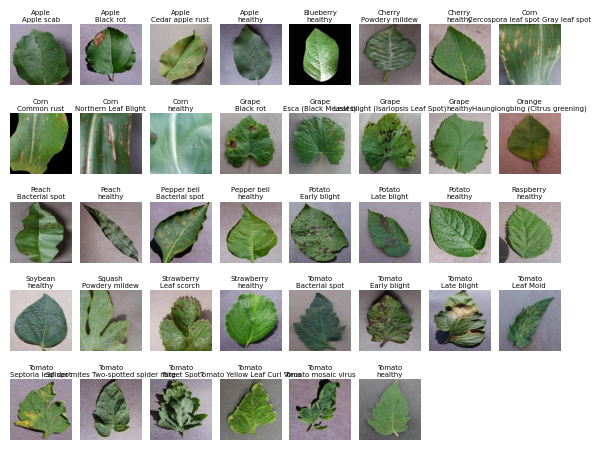

In [6]:
from src.experiments import plots as P, latex_tables as T, analysis as A

print(manifest.groupby("split").agg(images=("path", "size"), groups=("group_id", "nunique")).loc[["train", "val", "test"]])
print("groups in more than one split:", int((manifest.groupby("group_id")["split"].nunique() > 1).sum()))
A.write_tex(T.dataset_split(manifest), paths.tables / "split.tex")
P.class_distribution(manifest, paths.figures)
P.sample_grid(manifest, paths.data_root, paths.figures);

In [7]:
# Member 1's loader checks, then our GPU preprocessing against Member 1's CPU recipe
if not SMOKE:
    r = subprocess.run([sys.executable, "-m", "src.dataset.check_loaders", str(paths.manifest), str(paths.data_root)],
                       capture_output=True, text=True)
    print(r.stdout[-2500:], r.stderr[-1500:])
sample = manifest.groupby("label").head(1)["path"].map(lambda p: str(paths.data_root / p)).tolist()
r = subprocess.run([sys.executable, "-m", "tests.test_preprocess", *sample], capture_output=True, text=True)
print(r.stdout, r.stderr[-1500:])
assert r.returncode == 0

[PASS] mobilenetv2/train: size matches the manifest: 43,442 images
[PASS] mobilenetv2/train: batch shape and type: (32, 3, 224, 224) torch.float32
[PASS] mobilenetv2/train: values in (-1.0, 1.0): min -1.000, max 1.000
[PASS] mobilenetv2/train: labels are class numbers 0-37
[PASS] mobilenetv2/val: size matches the manifest: 5,431 images
[PASS] mobilenetv2/val: batch shape and type: (32, 3, 224, 224) torch.float32
[PASS] mobilenetv2/val: values in (-1.0, 1.0): min -1.000, max 1.000
[PASS] mobilenetv2/val: labels are class numbers 0-37
[PASS] mobilenetv2/test: size matches the manifest: 5,431 images
[PASS] mobilenetv2/test: batch shape and type: (32, 3, 224, 224) torch.float32
[PASS] mobilenetv2/test: values in (-1.0, 1.0): min -1.000, max 1.000
[PASS] mobilenetv2/test: labels are class numbers 0-37
[PASS] mobilenetv2: 38 classes
[PASS] mobilevit_xs/train: size matches the manifest: 43,442 images
[PASS] mobilevit_xs/train: batch shape and type: (32, 3, 256, 256) torch.float32
[PASS] mobil

## 2. Training
Same protocol for both models: AdamW (lr 1e-4, wd 1e-4), cosine schedule, batch 32, max 20 epochs,
early stopping on val loss (patience 5), best checkpoint by val loss, FP16 mixed precision.
Seeds 42, 43, 44, then the preprocessing ablation (seed 42).

In [8]:
from src.experiments.train import train_run

def log(msg):
    print(msg, flush=True)

# finished runs are skipped, unfinished ones resume from the last epoch saved on Drive
todo = main_runs(SEED_LIST) + (ablation_runs() if RUN_ABLATION and not SMOKE else [])
for i, (m, s, v) in enumerate(todo, 1):
    log(f"\n=== {i}/{len(todo)}: {run_name(m, s, v)} ===")
    train_run(paths, m, s, v, CFG, device=DEVICE, log=log)
log("\ntraining done")


=== 1/8: mobilenetv2_native_s42 ===
[mobilenetv2_native_s42] already finished, skipping

=== 2/8: mobilevit_xs_native_s42 ===
[mobilevit_xs_native_s42] already finished, skipping

=== 3/8: mobilenetv2_native_s43 ===
[mobilenetv2_native_s43] already finished, skipping

=== 4/8: mobilevit_xs_native_s43 ===
[mobilevit_xs_native_s43] already finished, skipping

=== 5/8: mobilenetv2_native_s44 ===
[mobilenetv2_native_s44] already finished, skipping

=== 6/8: mobilevit_xs_native_s44 ===
[mobilevit_xs_native_s44] already finished, skipping

=== 7/8: mobilenetv2_imagenet_s42 ===
[mobilenetv2_imagenet_s42] already finished, skipping

=== 8/8: mobilevit_xs_imagenet_s42 ===


config.json:   0%|          | 0.00/70.0k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 9.42MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/347 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 9.35MB            

model.safetensors: downloading bytes:           |  0.00B            

[mobilevit_xs_imagenet_s42] resuming after epoch 2 (best val loss 0.0601 at epoch 2)
[mobilevit_xs_imagenet_s42] epoch  3/10  train loss 0.0839 acc 0.9788 | val loss 0.0360 acc 0.9888 F1 0.9852 | 264s (165 img/s)  *best
[mobilevit_xs_imagenet_s42] epoch  4/10  train loss 0.0541 acc 0.9861 | val loss 0.0244 acc 0.9925 F1 0.9894 | 252s (172 img/s)  *best
[mobilevit_xs_imagenet_s42] epoch  5/10  train loss 0.0412 acc 0.9891 | val loss 0.0199 acc 0.9950 F1 0.9928 | 252s (172 img/s)  *best
[mobilevit_xs_imagenet_s42] epoch  6/10  train loss 0.0287 acc 0.9922 | val loss 0.0158 acc 0.9956 F1 0.9936 | 252s (172 img/s)  *best
[mobilevit_xs_imagenet_s42] epoch  7/10  train loss 0.0223 acc 0.9940 | val loss 0.0129 acc 0.9959 F1 0.9946 | 252s (172 img/s)  *best
[mobilevit_xs_imagenet_s42] epoch  8/10  train loss 0.0157 acc 0.9956 | val loss 0.0134 acc 0.9963 F1 0.9946 | 254s (171 img/s)
[mobilevit_xs_imagenet_s42] epoch  9/10  train loss 0.0129 acc 0.9968 | val loss 0.0102 acc 0.9972 F1 0.9954 | 2

## 3. E1: Classification performance

In [9]:
runs, preds = A.load_runs(paths)
main = A.main_results(runs)
per_seed = A.per_seed_table(runs)
stats = A.paired_statistics(preds)
cost = A.training_cost(runs)
for name, df in [("main", main), ("per_seed", per_seed), ("stats", stats), ("training_cost", cost)]:
    df.to_csv(paths.tables / f"{name}.csv", index=False)
A.write_tex(T.main_results(main), paths.tables / "main.tex")
A.write_tex(T.per_seed(per_seed), paths.tables / "per_seed.tex")
A.write_tex(T.statistics(stats), paths.tables / "stats.tex")
A.write_tex(T.training_cost(cost), paths.tables / "training_cost.tex")
display(main.round(3)); display(per_seed.round(4)); display(stats.round(4)); display(cost.round(2))

,model,seeds,accuracy_mean,accuracy_std,macro_precision_mean,macro_precision_std,macro_recall_mean,macro_recall_std,macro_f1_mean,macro_f1_std,errors_mean,errors_std
0,mobilenetv2,3,99.472,0.059,99.105,0.108,99.267,0.069,99.167,0.073,28.667,3.215
1,mobilevit_xs,3,99.681,0.021,99.375,0.024,99.553,0.045,99.457,0.035,17.333,1.155


,model,seed,accuracy,macro_precision,macro_recall,macro_f1,errors,best_epoch,epochs_run
0,mobilenetv2,42,0.9954,0.9919,0.9934,0.9924,25,9,10
1,mobilenetv2,43,0.9945,0.9915,0.9920,0.9917,30,6,10
2,mobilenetv2,44,0.9943,0.9898,0.9926,0.9909,31,8,10
3,mobilevit_xs,42,0.9967,0.9936,0.9951,0.9943,18,10,10
4,mobilevit_xs,43,0.9971,0.9940,0.9960,0.9950,16,10,10
5,mobilevit_xs,44,0.9967,0.9936,0.9955,0.9944,18,9,10


,seed,acc_diff_pp,acc_ci_low_pp,acc_ci_high_pp,f1_ci_low_pp,f1_ci_high_pp,only_mobilenetv2_right,only_mobilevit_right,mcnemar_p
0,42,0.1289,-0.0552,0.3130,-0.0597,0.4595,8,15,0.2100
1,43,0.2578,0.0737,0.4419,0.1027,0.5886,7,21,0.0125
2,44,0.2394,0.0552,0.4419,0.0462,0.6914,8,21,0.0241


,model,epochs_run_mean,epochs_run_std,best_epoch_mean,best_epoch_std,mean_epoch_train_time_s_mean,mean_epoch_train_time_s_std,total_train_time_s_mean,total_train_time_s_std,mean_train_images_per_s_mean,mean_train_images_per_s_std,peak_train_mem_mib_mean,peak_train_mem_mib_std,gpus
0,mobilenetv2,10.0,0.0,7.67,1.53,165.33,1.45,1724.66,12.91,263.28,2.05,1316.94,8.71,Tesla T4
1,mobilevit_xs,10.0,0.0,9.67,0.58,252.21,1.37,2611.21,14.99,172.27,0.93,2879.35,2.05,Tesla T4


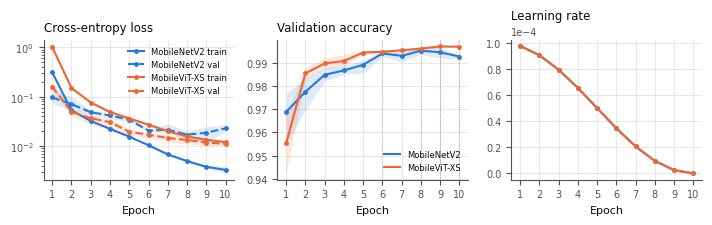

In [10]:
P.learning_curves(paths, runs, paths.figures);

,class,f1_mobilenetv2,f1_mobilevit_xs,f1_std_mobilenetv2,f1_std_mobilevit_xs,support,diff
24,Soybean___healthy,1.0000,0.9997,0.0000,0.0006,509,-0.0003
2,Apple___Cedar_apple_rust,1.0000,1.0000,0.0000,0.0000,27,0.0000
5,Cherry_(including_sour)___Powdery_mildew,1.0000,1.0000,0.0000,0.0000,105,0.0000
6,Cherry_(including_sour)___healthy,0.9941,0.9941,0.0000,0.0000,85,0.0000
13,Grape___Leaf_blight_(Isariopsis_Leaf_Spot),1.0000,1.0000,0.0000,0.0000,108,0.0000
14,Grape___healthy,1.0000,1.0000,0.0000,0.0000,42,0.0000
10,Corn_(maize)___healthy,1.0000,1.0000,0.0000,0.0000,116,0.0000
4,Blueberry___healthy,1.0000,1.0000,0.0000,0.0000,150,0.0000
23,Raspberry___healthy,1.0000,1.0000,0.0000,0.0000,37,0.0000
25,Squash___Powdery_mildew,1.0000,1.0000,0.0000,0.0000,184,0.0000


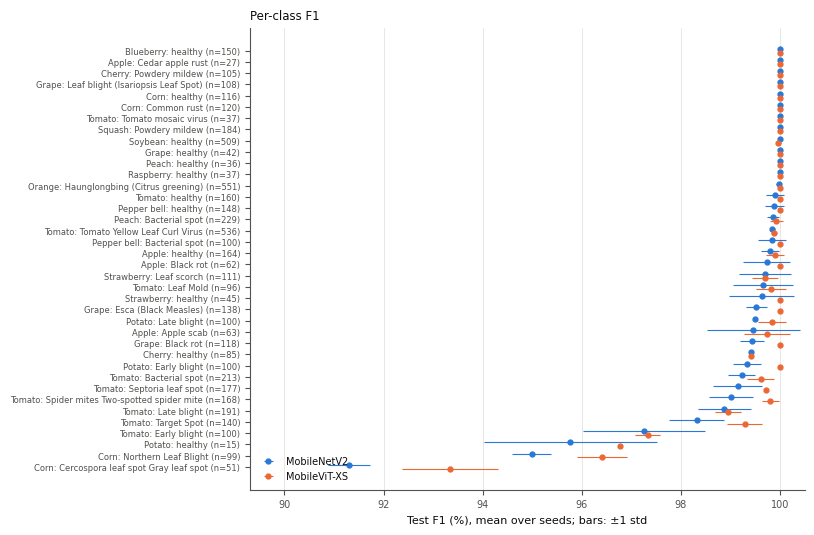

In [11]:
pc = A.per_class_table(preds)
pc.to_csv(paths.tables / "per_class.csv", index=False)
A.write_tex(T.per_class(pc), paths.tables / "per_class.tex")
P.per_class_f1(pc, paths.figures)
display(pc.sort_values("diff").round(4))

## 4. E2: Deployability
Both models benchmarked in the same session on the same hardware (seed-42 weights).

In [12]:
from src.experiments import storage
from src.experiments.benchmark import benchmark_model
from src.experiments.qualitative import load_best

bench_file = paths.results / "benchmark.json"  # delete to re-measure
class_names = sorted(manifest["label"].unique())
if bench_file.exists():
    bench = storage.load_json(bench_file)
else:
    BCFG = BenchmarkConfig() if not SMOKE else BenchmarkConfig(runs=10, warmup=2, throughput_runs=3)
    bench = {}
    for m in MODEL_ORDER:
        model = load_best(paths, run_name(m, 42), m, class_names)
        bench[m] = benchmark_model(model, m, BCFG, log=log)
        del model
    storage.save_json(bench, bench_file)
dep = A.deployability(bench)
dep.to_csv(paths.tables / "deployability.csv", index=False)
A.write_tex(T.deployability(dep), paths.tables / "deployability.tex")
display(dep.round(3).T)

config.json:   0%|          | 0.00/69.8k [00:00<?, ?B/s]

  mobilenetv2: CPU latency (1 thread(s))
  mobilenetv2: CPU latency (all thread(s))
  mobilenetv2: GPU latency, throughput, memory
  mobilevit_xs: CPU latency (1 thread(s))
  mobilevit_xs: CPU latency (all thread(s))
  mobilevit_xs: GPU latency, throughput, memory


,0,1
model,mobilenetv2,mobilevit_xs
input,224,256
params_m,2.273,1.947
size_mb_fp32,9.33,7.942
size_mb_fp16,4.716,4.028
gmacs,0.3,1.026
gflops,0.599,2.051
cpu1_ms,42.214,72.689
cpu1_std,12.293,12.819
cpuall_ms,41.704,62.634


## 5. E3: Accuracy vs cost

,quantity,mobilevit_vs_mobilenetv2,kind
0,Accuracy (pp),0.209,difference
1,Macro F1 (pp),0.291,difference
2,Parameters,0.857,ratio
3,File size (FP32),0.851,ratio
4,MACs,3.424,ratio
5,"GPU latency (FP32, bs 1)",1.641,ratio
6,"GPU latency (FP16, bs 1)",1.756,ratio
7,CPU latency (1 thread),1.722,ratio
8,CPU latency (all threads),1.502,ratio
9,GPU throughput,0.521,ratio


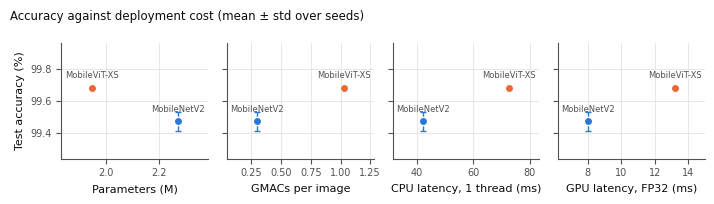

In [13]:
tr = A.tradeoff(main, dep)
tr.to_csv(paths.tables / "tradeoff.csv", index=False)
A.write_tex(T.tradeoff(tr), paths.tables / "tradeoff.tex")
display(tr.round(3))
P.tradeoff(main, dep, paths.figures);

## 6. E4: Qualitative results

,model,true,predicted,mean_count,class_size
0,mobilenetv2,Corn_(maize)___Northern_Leaf_Blight,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,7.333333,99
1,mobilenetv2,Tomato___Early_blight,Tomato___Late_blight,3.666667,100
2,mobilenetv2,Tomato___Target_Spot,Tomato___Spider_mites Two-spotted_spider_mite,2.666667,140
3,mobilenetv2,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,Corn_(maize)___Northern_Leaf_Blight,2.000000,51
4,mobilenetv2,Tomato___Septoria_leaf_spot,Tomato___Bacterial_spot,1.666667,177
5,mobilenetv2,Grape___Black_rot,Grape___Esca_(Black_Measles),1.333333,118
6,mobilenetv2,Cherry_(including_sour)___healthy,Potato___healthy,1.000000,85
7,mobilenetv2,Tomato___Early_blight,Tomato___Target_Spot,1.000000,100
8,mobilevit_xs,Corn_(maize)___Northern_Leaf_Blight,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,5.000000,99
9,mobilevit_xs,Tomato___Early_blight,Tomato___Late_blight,2.000000,100


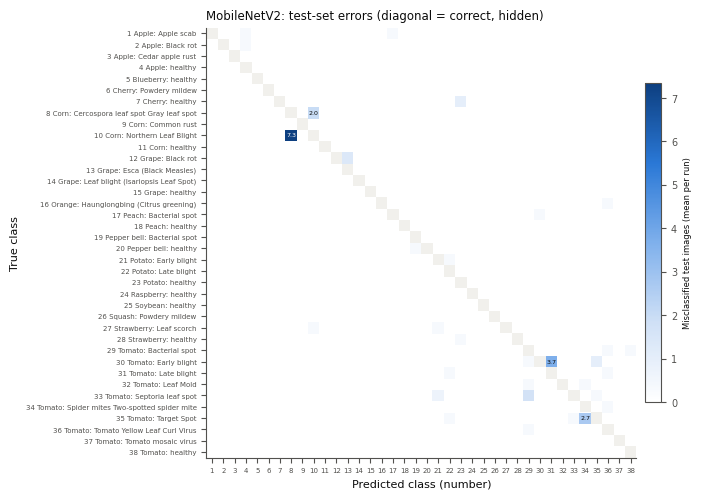

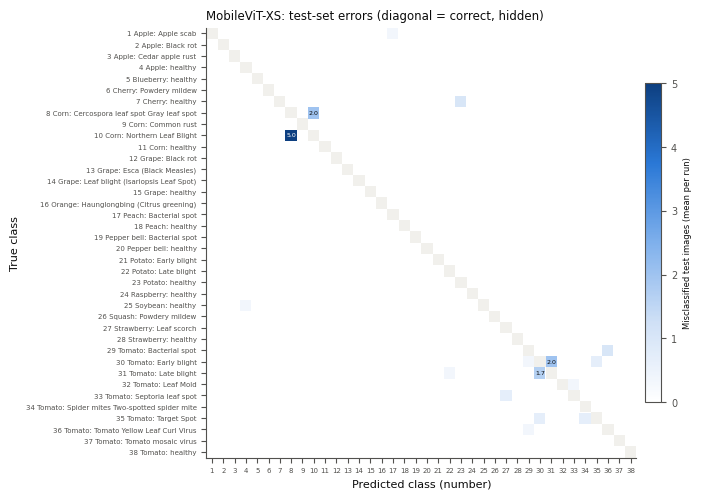

In [14]:
tc = A.top_confusions_all(preds)
tc.to_csv(paths.tables / "top_confusions.csv", index=False)
A.write_tex(T.top_confusions(tc), paths.tables / "top_confusions.tex")
display(tc)
for m in MODEL_ORDER:
    P.confusion_errors(A.mean_confusion(preds, m), class_names, m, paths.figures)

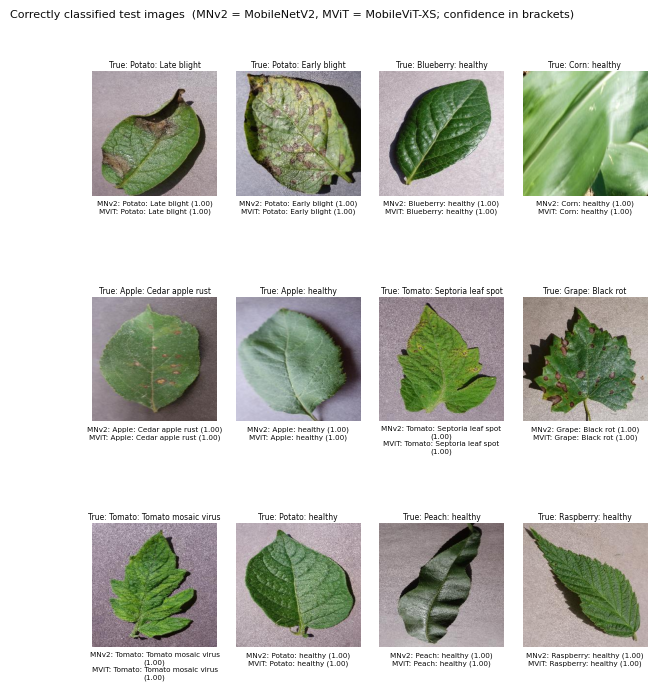

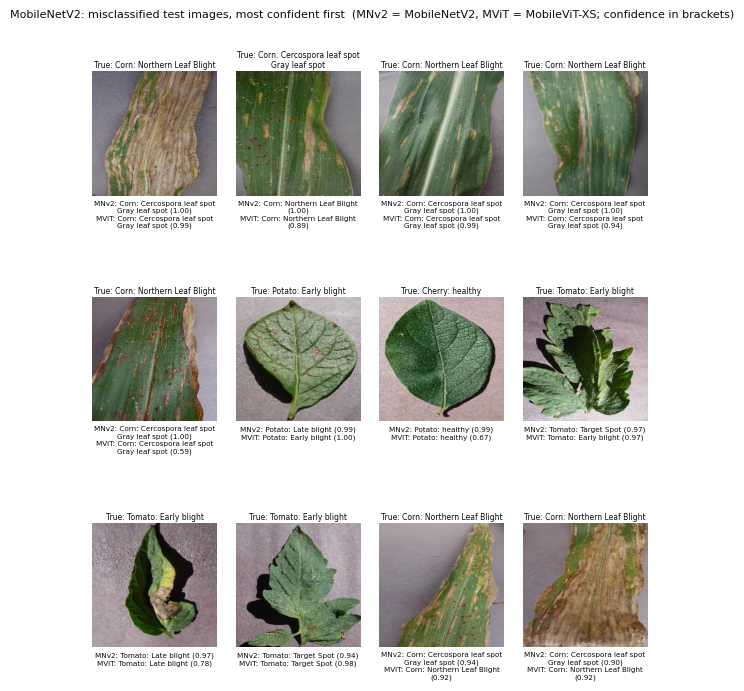

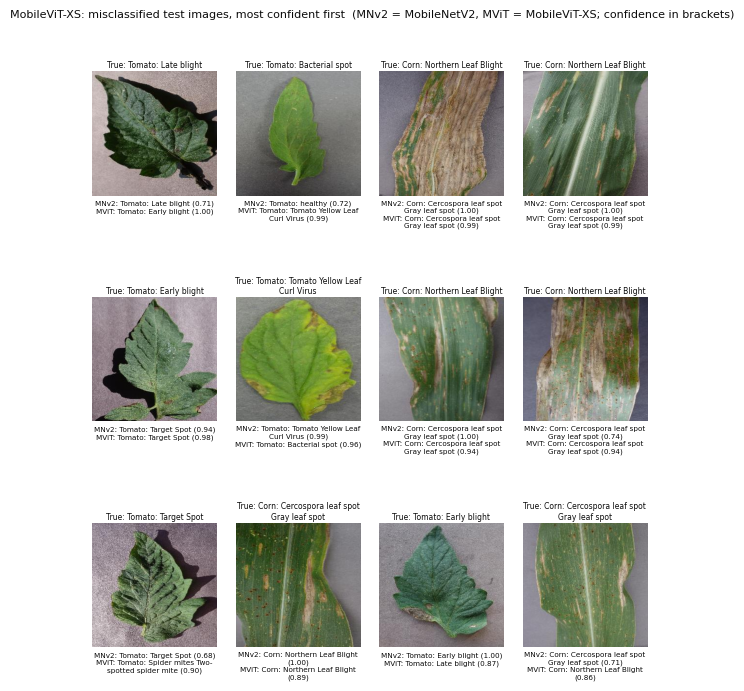

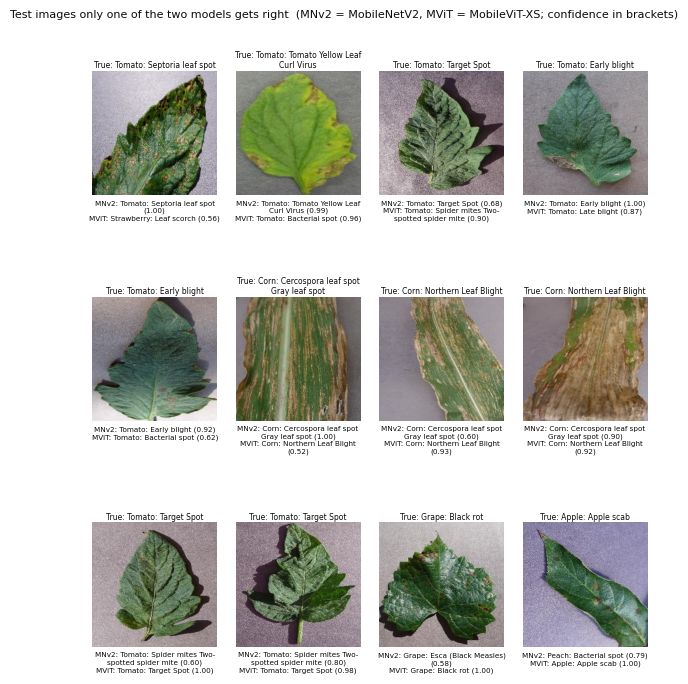

In [15]:
from src.experiments import qualitative as Q

pair = Q.pair_for_seed(preds, 42)
P.example_grid(Q.select_examples(pair, "correct", 12), paths.data_root, paths.figures, "e4_correct",
               "Correctly classified test images")
for m in MODEL_ORDER:
    items = Q.select_examples(pair, m, 12)
    if items:
        P.example_grid(items, paths.data_root, paths.figures, f"e4_failures_{m}",
                       f"{MODELS[m]['display']}: misclassified test images, most confident first")
items = Q.select_examples(pair, "disagree", 12)
if items:
    P.example_grid(items, paths.data_root, paths.figures, "e4_disagreements",
                   "Test images only one of the two models gets right")

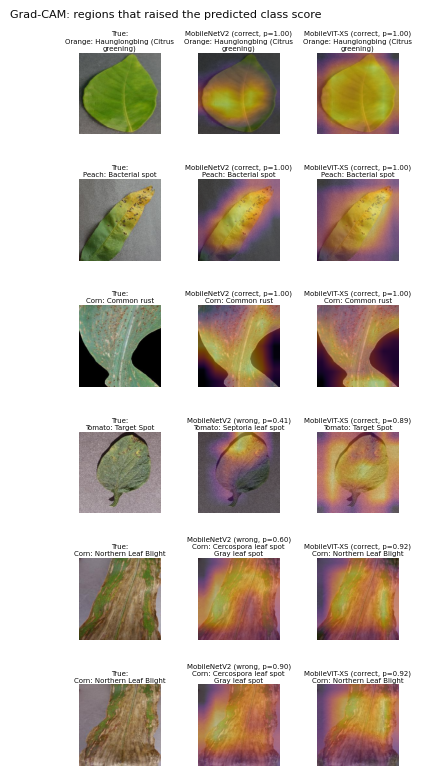

In [16]:
cam_models = {m: load_best(paths, run_name(m, 42), m, class_names, DEVICE) for m in MODEL_ORDER}
rows = Q.gradcam_rows(cam_models, pair, Q.gradcam_indices(pair, 3, 3), paths.data_root, DEVICE)
P.gradcam_grid(rows, paths.figures);

## 7. E5: Robustness to image corruptions
All trained models on the test set with noise, blur, low brightness, low contrast, JPEG compression and
low resolution (3 severities each). No retraining.

  clean           s0: mobilenetv2 0.9947  mobilevit_xs 0.9968
  gaussian_noise  s1: mobilenetv2 0.8558  mobilevit_xs 0.9055
  gaussian_noise  s2: mobilenetv2 0.4685  mobilevit_xs 0.5636
  gaussian_noise  s3: mobilenetv2 0.2080  mobilevit_xs 0.2503
  gaussian_blur   s1: mobilenetv2 0.9543  mobilevit_xs 0.9284
  gaussian_blur   s2: mobilenetv2 0.6990  mobilevit_xs 0.6224
  gaussian_blur   s3: mobilenetv2 0.4973  mobilevit_xs 0.4713
  low_brightness  s1: mobilenetv2 0.9934  mobilevit_xs 0.9962
  low_brightness  s2: mobilenetv2 0.9864  mobilevit_xs 0.9947
  low_brightness  s3: mobilenetv2 0.8991  mobilevit_xs 0.9820
  low_contrast    s1: mobilenetv2 0.9932  mobilevit_xs 0.9959
  low_contrast    s2: mobilenetv2 0.9866  mobilevit_xs 0.9924
  low_contrast    s3: mobilenetv2 0.9106  mobilevit_xs 0.9583
  jpeg            s1: mobilenetv2 0.9500  mobilevit_xs 0.9446
  jpeg            s2: mobilenetv2 0.7967  mobilevit_xs 0.7115
  jpeg            s3: mobilenetv2 0.2846  mobilevit_xs 0.1434
  low_re

,model,corruption,accuracy_mean,accuracy_std,drop_pp_mean,drop_pp_std
0,mobilenetv2,gaussian_blur,0.7169,0.0307,27.7849,3.0168
1,mobilenetv2,gaussian_noise,0.5108,0.0858,48.3930,8.6306
2,mobilenetv2,jpeg,0.6771,0.0329,31.7642,3.2540
3,mobilenetv2,low_brightness,0.9596,0.0356,3.5107,3.5187
4,mobilenetv2,low_contrast,0.9635,0.0234,3.1240,2.2983
5,mobilenetv2,low_resolution,0.6231,0.0397,37.1632,3.9102
6,mobilevit_xs,gaussian_blur,0.6740,0.0579,32.2777,5.8072
7,mobilevit_xs,gaussian_noise,0.5731,0.0525,42.3679,5.2585
8,mobilevit_xs,jpeg,0.5998,0.0322,39.6960,3.2320
9,mobilevit_xs,low_brightness,0.9910,0.0017,0.5831,0.1748


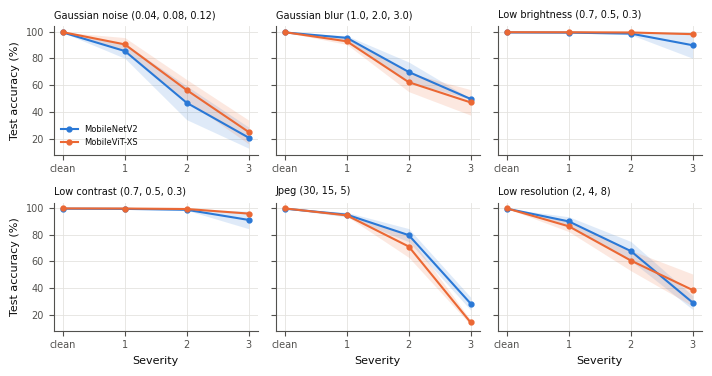

In [17]:
from src.experiments.robustness import evaluate_corruptions, summarise_robustness

rob_file = paths.tables / "robustness_raw.csv"
if RUN_ROBUSTNESS:
    if rob_file.exists():
        rob = pd.read_csv(rob_file)
    else:
        models = {r["run"]: (r["model"], load_best(paths, r["run"], r["model"], class_names, DEVICE))
                  for _, r in runs.iterrows()}
        rob = evaluate_corruptions(models, paths, DEVICE, num_workers=CFG.num_workers, log=log)
        storage.save_dataframe(rob, rob_file)
        del models
    rsum = summarise_robustness(rob)
    rsum.to_csv(paths.tables / "robustness.csv", index=False)
    clean = {m: A.mean_std(rob[(rob.corruption == "clean") & (rob.model == m)]["accuracy"]) for m in MODEL_ORDER}
    A.write_tex(T.robustness(rsum, clean), paths.tables / "robustness.tex")
    display(rsum.round(4))
    P.robustness(rob, paths.figures);

## 8. E6: Preprocessing ablation (ImageNet mean/std vs each model's own preprocessing)

In [18]:
abl_runs, _ = A.load_runs(paths, variant="imagenet")
if len(abl_runs):
    ab = A.ablation_table(runs, abl_runs)
    ab.to_csv(paths.tables / "ablation.csv", index=False)
    A.write_tex(T.ablation(ab), paths.tables / "ablation.tex")
    display(ab.round(3))
else:
    print("no ablation runs yet")

,model,seed,native_acc,imagenet_acc,native_f1,imagenet_f1,native_best_epoch,imagenet_best_epoch,acc_diff_pp,f1_diff_pp
0,mobilenetv2,42,99.540,99.448,99.241,99.099,9,9,-0.092,-0.142
1,mobilevit_xs,42,99.669,99.650,99.433,99.398,10,10,-0.018,-0.035


## 9. Summary

In [19]:
summary = {
    "main": main.to_dict("records"), "stats": stats.to_dict("records"), "training_cost": cost.to_dict("records"),
    "deployability": dep.to_dict("records"), "tradeoff": tr.to_dict("records"),
    "robustness": rsum.to_dict("records") if RUN_ROBUSTNESS else None,
    "ablation": ab.to_dict("records") if len(abl_runs) else None,
    "environment": storage.load_json(paths.run_dir(run_name(MODEL_ORDER[0], 42)) / "config.json")["environment"],
}
storage.save_json(summary, paths.results / "summary.json")
best = main.loc[main["macro_f1_mean"].idxmax()]
print(f"best macro-F1: {MODELS[best['model']]['display']} {best['macro_f1_mean']:.2f} ± {best['macro_f1_std']:.2f} %")

best macro-F1: MobileViT-XS 99.46 ± 0.03 %


## 10. Edge deployment
The seed-42 models are exported to ONNX and checked against PyTorch. `edge/phone_benchmark.html` runs these
files on a smartphone with ONNX Runtime Web (WebAssembly, one thread, FP32), with the same timing protocol as E2.
The phone's saved result is loaded below and compared with the GPU and CPU latencies.

*This section needs no GPU. It was run on 22 November 2026 on a CPU machine outside Colab, because the Colab GPU quota was not available, with the same seed-42 checkpoints (`best.pt`) saved by section 2.*

In [22]:
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "onnx", "onnxscript", "onnxruntime"], check=True)
from edge.export_onnx import export

onnx_report = export(paths.runs, paths.results / "onnx")
onnx_report

[torch.onnx] Obtain model graph for `Classifier([...]` with `torch.export.export(..., strict=False)`...


[torch.onnx] Obtain model graph for `Classifier([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...


[torch.onnx] Optimize the ONNX graph... ✅


[torch.onnx] Obtain model graph for `Classifier([...]` with `torch.export.export(..., strict=False)`...


[torch.onnx] Obtain model graph for `Classifier([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...


[torch.onnx] Optimize the ONNX graph... ✅


,onnx_mb,max_abs_diff,same_prediction,check_top_class,check_score
mobilenetv2,9.370285,0.000004,True,10,3.01959
mobilevit_xs,9.331386,0.000011,True,10,9.678464


In [23]:
import json

phone = json.load(open("edge/results/tecno_spark_20_pro_plus.json"))
rows = []
if "gpu_fp32" in bench[MODEL_ORDER[0]]:
    rows.append(("T4 GPU, PyTorch FP32", *(bench[m]["gpu_fp32"]["mean_ms"] for m in MODEL_ORDER)))
rows.append(("Colab CPU, 1 core, PyTorch FP32", *(bench[m]["cpu_1t"]["mean_ms"] for m in MODEL_ORDER)))
rows.append((f"{phone['device']}, {phone['runtime']}", *(phone["results"][m]["mean"] for m in MODEL_ORDER)))
platforms = pd.DataFrame(rows, columns=["platform", "mobilenetv2_ms", "mobilevit_xs_ms"])
platforms["ratio"] = platforms["mobilevit_xs_ms"] / platforms["mobilenetv2_ms"]
platforms.to_csv(paths.tables / "platforms.csv", index=False)
platforms.round(2)

,platform,mobilenetv2_ms,mobilevit_xs_ms,ratio
0,"T4 GPU, PyTorch FP32",8.03,13.18,1.64
1,"Colab CPU, 1 core, PyTorch FP32",42.21,72.69,1.72
2,"Tecno Spark 20 Pro+, onnxruntime-web 1.20.1, W...",109.30,352.45,3.22


In [24]:
from IPython.display import Code
display(Code(filename="edge/export_onnx.py", language="python"))

"""Export the fine-tuned seed-42 models to ONNX and check them against PyTorch.

The ONNX files are what edge/phone_benchmark.html runs on a phone (ONNX Runtime Web).
Usage (repo root): python -m edge.export_onnx <runs_dir> <out_dir>
  runs_dir: the Drive folder with <model>_native_s42/best.pt
"""
import sys
from pathlib import Path

import numpy as np
import onnxruntime as ort
import pandas as pd
import torch

from src.experiments.config import MODEL_ORDER, MODELS, run_name
from src.experiments.models import build_model


def export(runs_dir, out_dir, seed=42):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    names = sorted(pd.read_csv("splits/manifest.csv")["label"].unique())
    torch.manual_seed(0)
    report = {}
    for key in MODEL_ORDER:
        model = build_model(key, names, pretrained=False)
        state = torch.load(Path(runs_dir) / run_name(key, seed) / "best.pt", map_location="cpu")
        model.load_state_dict(state)
        model.eval()
        size = MODELS[key]["input_size"]
        x = torch.randn(1, 3, size, size)
        path = out_dir / f"{key}.onnx"
        torch.onnx.export(model, (x,), str(path), input_names=["pixel_values"], output_names=["logits"],
                          opset_version=18, dynamo=True, external_data=False)

        session = ort.InferenceSession(str(path), providers=["CPUExecutionProvider"])
        with torch.no_grad():
            ref = model(x).numpy()
        out = session.run(None, {"pixel_values": x.numpy()})[0]
        # the fixed input the phone page also uses to check that it computes the same function
        grey = np.full((1, 3, size, size), 0.5, np.float32)
        logits = session.run(None, {"pixel_values": grey})[0][0]
        report[key] = {"onnx_mb": path.stat().st_size / 1e6, "max_abs_diff": float(np.abs(out - ref).max()),
                       "same_prediction": bool((out.argmax(1) == ref.argmax(1)).all()),
                       "check_top_class": int(logits.argmax()), "check_score": float(logits.max())}
    return pd.DataFrame(report).T


if __name__ == "__main__":
    print(export(sys.argv[1], sys.argv[2]).to_string())

## Appendix: source code

In [20]:
from IPython.display import Code

for f in ["config", "data", "models", "train", "evaluate", "benchmark", "robustness", "gradcam",
          "qualitative", "analysis", "latex_tables", "plots", "storage"]:
    display(Code(filename=f"src/experiments/{f}.py", language="python"))
for f in ["datasets", "preprocessing"]:
    display(Code(filename=f"src/dataset/{f}.py", language="python"))

"""Single place for every experimental setting.

All values follow the proposal (Methodology, Section IV-D) unless a comment says otherwise.
Change nothing here between the two models: the comparison is only fair if both runs share it.
"""
from __future__ import annotations

from dataclasses import asdict, dataclass, replace
from pathlib import Path

# ---------------------------------------------------------------------------------------------
# Models. Checkpoint names were confirmed with Member 1; their preprocessor configs were read
# and src/dataset/preprocessing.py reproduces them (see tests/test_preprocessing_matches_hf.py).
# ---------------------------------------------------------------------------------------------
MODELS = {
    "mobilenetv2": {
        "checkpoint": "google/mobilenet_v2_1.0_224",
        "display": "MobileNetV2",
        "family": "CNN",
        "input_size": 224,
        # last convolutional feature map (1280 x 7 x 7) used for Grad-CAM
        "cam_layer": "net.mobilenet_v2.conv_1x1",
    },
    "mobilevit_xs": {
        "checkpoint": "apple/mobilevit-x-small",
        "display": "MobileViT-XS",
        "family": "Hybrid CNN-ViT",
        "input_size": 256,
        # last convolutional feature map (384 x 8 x 8), after the final MobileViT block
        "cam_layer": "net.mobilevit.conv_1x1_exp",
    },
}
MODEL_ORDER = ["mobilenetv2", "mobilevit_xs"]

# Preprocessing variants. "native" is Member 1's recipe (the main experiments). "imagenet" is the
# proposal's original ImageNet mean/std in RGB, used only for the preprocessing ablation (E6).
PREPROCESSING_VARIANTS = ("native", "imagenet")
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

# Training seeds. The data split is fixed (seed 42, splits/manifest.csv); only model
# initialisation of the new head, data order, augmentation and dropout change between seeds.
SEEDS = (42, 43, 44)
ABLATION_SEED = 42


@dataclass(frozen=True)
class TrainConfig:
    # --- proposal, Section IV-D -----------------------------------------------------------
    epochs: int = 10                 # maximum epochs (proposal: 20; reduced for the Colab GPU budget)
    batch_size: int = 32
    lr: float = 1e-4                 # AdamW initial learning rate
    weight_decay: float = 1e-4       # decoupled weight decay (AdamW), applied to all parameters
    patience: int = 5                # early stopping on validation loss
    min_delta: float = 0.0           # an epoch counts as an improvement if val loss decreases
    # --- implementation choices (same for both models) ------------------------------------
    scheduler: str = "cosine_per_step"   # cosine annealing to 0 over `epochs`, stepped per batch
    amp: bool = True                 # FP16 mixed precision on CUDA (T4 tensor cores); off on CPU
    eval_batch_size: int = 128       # evaluation only; does not change results (BN in eval mode)
    num_workers: int = 2             # Colab free tier has 2 vCPUs
    prefetch_factor: int = 4
    label_smoothing: float = 0.0     # plain categorical cross-entropy, as in the proposal
    grad_clip_norm: float | None = None   # not used (not in the proposal)
    # --- limits for quick local tests (None = full data) ----------------------------------
    max_train_batches: int | None = None
    max_eval_batches: int | None = None

    def to_dict(self):
        return asdict(self)

    def with_overrides(self, **kw):
        return replace(self, **kw)


@dataclass(frozen=True)
class BenchmarkConfig:
    # proposal, Section IV-E: 100 timed runs after 10 warm-up runs, batch size 1
    warmup: int = 10
    runs: int = 100
    batch_size: int = 1
    throughput_batch_size: int = 32
    throughput_runs: int = 30
    cpu_threads: tuple = (1, 0)      # 0 = all available cores


@dataclass
class Paths:
    """Where everything lives. On Colab `persist` is a Google Drive folder, so it survives
    disconnects; `local_data` is the fast local disk copy of the images."""
 

"""Data loading built on Member 1's manifest and image recipes.

Speed: Colab's free tier has 2 CPU cores, which cannot run augmentation and resizing fast enough
for the GPU (about 160 images/s). So the workers only decode JPEGs into uint8 tensors, and the
recipe (the same augmentation, resize, scaling, normalisation and channel order as
src/dataset/preprocessing.py) runs on the GPU in `Preprocess`. tests/test_preprocess.py checks it
against Member 1's CPU recipe.

Reproducibility: shuffling depends only on (seed, epoch) and augmentation draws from the global
torch RNG, which the trainer re-seeds every epoch, so a resumed run sees the same batches.
"""
from __future__ import annotations

import io

import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageEnhance, ImageFilter
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import InterpolationMode, v2

from src.dataset.datasets import _seed_worker
from src.dataset.preprocessing import SPECS, augmentation

from .config import IMAGENET_MEAN, IMAGENET_STD

IMAGE_SIZE = 256   # every PlantVillage image is 256 x 256 (reports/audit.md)


# ---------------------------------------------------------------------------------------------
# dataset: decoded uint8 images
# ---------------------------------------------------------------------------------------------
def load_uint8(path) -> torch.Tensor:
    with Image.open(path) as im:
        im = im.convert("RGB")
    if im.size != (IMAGE_SIZE, IMAGE_SIZE):
        im = im.resize((IMAGE_SIZE, IMAGE_SIZE), Image.BILINEAR)
    return torch.from_numpy(np.asarray(im).copy()).permute(2, 0, 1)   # 3 x H x W, uint8, RGB


class ImageDataset(Dataset):
    """Same rows, labels and class numbering as src.dataset.datasets.PlantVillageDataset."""

    def __init__(self, manifest_csv, data_root, split):
        from pathlib import Path
        m = pd.read_csv(manifest_csv)
        self.classes = sorted(m["label"].unique())
        index = {c: i for i, c in enumerate(self.classes)}
        rows = m[m["split"] == split]
        self.root = Path(data_root)
        self.paths = rows["path"].tolist()
        self.labels = [index[c] for c in rows["label"]]

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        return load_uint8(self.root / self.paths[i]), self.labels[i]


# ---------------------------------------------------------------------------------------------
# the model recipe, on the GPU
# ---------------------------------------------------------------------------------------------
class Preprocess(nn.Module):
    """uint8 RGB batch [B, 3, 256, 256] -> model input. `native` is Member 1's recipe; `imagenet`
    (ablation only) uses RGB and the ImageNet mean/std from the original proposal."""

    def __init__(self, model_key: str, variant: str = "native"):
        super().__init__()
        spec = SPECS[model_key]
        self.size = spec["size"]
        if variant == "native":
            mean, std, self.bgr = spec["mean"], spec["std"], spec["bgr"]
        elif variant == "imagenet":
            mean, std, self.bgr = IMAGENET_MEAN, IMAGENET_STD, False
        else:
            raise ValueError(f"unknown preprocessing variant {variant!r}")
        self.normalize = mean is not None
        self.register_buffer("mean", torch.tensor(mean or (0.0, 0.0, 0.0)).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(std or (1.0, 1.0, 1.0)).view(1, 3, 1, 1))
        self.augment = v2.Compose(augmentation())   # flip, rotation +-15, brightness/contrast 0.2

    @torch.no_grad()
    def forward(self, x: torch.Tensor, train: bool) -> torch.Tensor:
        if train:
            # per image, so every image gets its own random parameters
            x = torch.stack([self.augment(img) for img in x])
        x = x.float()
        if x.shape[-1] != self.size:
            x = v2.functional.resize(x, [self.size, self.size], interpolation=Interpolati

"""Model construction. Only the ImageNet classification head is replaced (38 classes); the
pretrained architectures are not modified, as stated in the proposal (Section IV-B)."""
from __future__ import annotations

import io

import torch
from torch import nn

from .config import MODELS


class Classifier(nn.Module):
    """Thin wrapper so every model is called as `model(x) -> logits` (plain tensors in and out).
    This keeps training, FLOP counting, latency timing and Grad-CAM identical for both models."""

    def __init__(self, net: nn.Module, model_key: str):
        super().__init__()
        self.net = net
        self.model_key = model_key

    def forward(self, x):
        return self.net(pixel_values=x).logits


def build_model(model_key: str, class_names, pretrained: bool = True) -> Classifier:
    """ImageNet-pretrained backbone from Hugging Face with a fresh 38-class head.

    pretrained=False builds the same architecture with random weights (offline tests only)."""
    from transformers import AutoConfig, AutoModelForImageClassification
    from transformers.utils import logging as hf_logging

    spec = MODELS[model_key]
    id2label = {i: c for i, c in enumerate(class_names)}
    label2id = {c: i for i, c in id2label.items()}
    kwargs = dict(id2label=id2label, label2id=label2id)   # 38 labels -> 38-class head
    if pretrained:
        # the head size changes (1001/1000 -> 38), so the old head is dropped and re-initialised;
        # the library reports that at length, which is expected here, so its log is muted
        verbosity = hf_logging.get_verbosity()
        hf_logging.set_verbosity_error()
        try:
            net = AutoModelForImageClassification.from_pretrained(
                spec["checkpoint"], ignore_mismatched_sizes=True, **kwargs)
        finally:
            hf_logging.set_verbosity(verbosity)
    else:
        config = AutoConfig.from_pretrained(spec["checkpoint"], **kwargs)
        net = AutoModelForImageClassification.from_config(config)
    model = Classifier(net, model_key)
    head = model.net.classifier
    assert head.out_features == len(class_names), "classification head was not replaced"
    return model


def count_parameters(model: nn.Module):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


def state_dict_size_mb(model: nn.Module, dtype=torch.float32) -> float:
    """Size of the saved weights (torch.save of the state dict) in MB (10^6 bytes)."""
    sd = {k: (v.to(dtype) if v.is_floating_point() else v) for k, v in model.state_dict().items()}
    buf = io.BytesIO()
    torch.save(sd, buf)
    return buf.getbuffer().nbytes / 1e6

"""Resumable fine-tuning of one (model, seed, preprocessing) run.

A run folder on persistent storage (Google Drive on Colab) holds:
  config.json            settings, library versions and hardware of the run
  last.pt                full training state after the latest finished epoch (deleted when done)
  best.pt                weights with the lowest validation loss so far
  history.csv            one row per epoch
  test_predictions.npz   test logits, labels and image paths of the best checkpoint
  metrics.json           test metrics of the best checkpoint
  summary.json           everything needed for the results tables
  DONE                   written last; a run with DONE is never trained again

Calling `train_run` again after a disconnect continues from `last.pt`. Because data order,
augmentation and dropout depend only on (seed, epoch), the resumed run sees the same batches it
would have seen without the interruption.
"""
from __future__ import annotations

import math
import platform
import random
import shutil
import time

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from . import storage
from .config import MODELS, TrainConfig, run_name
from .data import Preprocess, make_loaders
from .evaluate import classification_metrics, predict
from .models import build_model, count_parameters

PIPELINE = "gpu-preprocess-v1"   # recorded in config.json; runs from another pipeline are redone


def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def environment_info(device: str) -> dict:
    import transformers
    info = {
        "python": platform.python_version(),
        "torch": torch.__version__,
        "transformers": transformers.__version__,
        "device": device,
        "cpu": platform.processor() or platform.machine(),
        "cpu_count": __import__("os").cpu_count(),
    }
    if device == "cuda":
        info["gpu"] = torch.cuda.get_device_name(0)
        info["cuda"] = torch.version.cuda
        info["cudnn"] = torch.backends.cudnn.version()
    return info


def _cosine(total_steps: int):
    return lambda step: 0.5 * (1.0 + math.cos(math.pi * min(step, total_steps) / total_steps))


def _train_one_epoch(model, loader, prep, optimizer, scheduler, scaler, device, cfg):
    model.train()
    use_amp = cfg.amp and device == "cuda"
    loss_sum = torch.zeros((), device=device)
    correct = torch.zeros((), device=device, dtype=torch.long)
    n = 0
    for i, (x, y) in enumerate(loader):
        if cfg.max_train_batches is not None and i >= cfg.max_train_batches:
            break
        x = prep(x.to(device, non_blocking=True), train=True)
        y = y.to(device, non_blocking=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            logits = model(x)
            loss = F.cross_entropy(logits, y, label_smoothing=cfg.label_smoothing)
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        if cfg.grad_clip_norm is not None:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip_norm)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        # accumulate on the GPU: no .item() per step, so no CPU-GPU synchronisation per batch
        loss_sum += loss.detach().float() * y.numel()
        correct += (logits.argmax(1) == y).sum()
        n += y.numel()
    loss = (loss_sum / max(n, 1)).item()
    if not math.isfinite(loss):
        raise FloatingPointError("training loss is not finite; stopping this run")
    return loss, correct.item() / max(n, 1), n


def train_run(paths, model_key, seed, variant="native", cfg: TrainConfig = TrainConfig(),
              device=None, pretrained=True, log=print):
    """Train (or resume, or skip if finished) one run and return its summary dict."""
    device = device or ("cuda" if 

"""Predictions, metrics and statistical comparison of the two models.

Metrics follow the proposal (Section IV-E): accuracy and macro-averaged F1 (each of the 38 classes
weighted equally). Macro precision and recall are reported as well, since the guidance asks for
all relevant metrics and they explain where F1 comes from."""
from __future__ import annotations

import numpy as np
import pandas as pd
import torch
from scipy.stats import binomtest
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_recall_fscore_support)


@torch.inference_mode()
def predict(model, loader, prep, device, amp=False, max_batches=None):
    """Returns (logits float32 [N, C], labels int64 [N], mean cross-entropy loss).
    `prep` turns the loader's uint8 images into model input (data.Preprocess)."""
    model.eval()
    logits_all, labels_all = [], []
    loss_sum, n = 0.0, 0
    use_amp = amp and device == "cuda"
    for i, (x, y) in enumerate(loader):
        if max_batches is not None and i >= max_batches:
            break
        x = prep(x.to(device, non_blocking=True), train=False)
        y = y.to(device, non_blocking=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            logits = model(x)
        logits = logits.float()
        loss_sum += torch.nn.functional.cross_entropy(logits, y, reduction="sum").item()
        n += y.numel()
        logits_all.append(logits.cpu())
        labels_all.append(y.cpu())
    logits = torch.cat(logits_all).numpy().astype(np.float32)
    labels = torch.cat(labels_all).numpy().astype(np.int64)
    return logits, labels, loss_sum / max(n, 1)


def classification_metrics(labels, preds, num_classes):
    """Overall metrics as a flat dict (fractions, not percentages)."""
    p, r, f1, _ = precision_recall_fscore_support(
        labels, preds, labels=np.arange(num_classes), average="macro", zero_division=0)
    return {
        "accuracy": float(accuracy_score(labels, preds)),
        "macro_precision": float(p),
        "macro_recall": float(r),
        "macro_f1": float(f1),
        "n": int(len(labels)),
        "errors": int((labels != preds).sum()),
    }


def per_class_metrics(labels, preds, class_names):
    p, r, f1, support = precision_recall_fscore_support(
        labels, preds, labels=np.arange(len(class_names)), average=None, zero_division=0)
    return pd.DataFrame({"class": class_names, "precision": p, "recall": r, "f1": f1,
                         "support": support})


def confusion(labels, preds, num_classes, normalize=None):
    return confusion_matrix(labels, preds, labels=np.arange(num_classes), normalize=normalize)


def top_confusions(labels, preds, class_names, k=10):
    cm = confusion(labels, preds, len(class_names))
    np.fill_diagonal(cm, 0)
    idx = np.dstack(np.unravel_index(np.argsort(-cm, axis=None), cm.shape))[0][:k]
    rows = [{"true": class_names[i], "predicted": class_names[j], "count": int(cm[i, j]),
             "share_of_true_class": float(cm[i, j] / max((labels == i).sum(), 1))}
            for i, j in idx if cm[i, j] > 0]
    return pd.DataFrame(rows)


# ---------------------------------------------------------------------------------------------
# aggregation over seeds and paired statistics
# ---------------------------------------------------------------------------------------------
def mean_std(values):
    """Mean and sample standard deviation (ddof=1; 0 when only one value)."""
    a = np.asarray(values, dtype=float)
    return float(a.mean()), float(a.std(ddof=1)) if a.size > 1 else 0.0


def mcnemar_exact(labels, pred_a, pred_b):
    """Exact McNemar test on the same test images. b = A right & B wrong, c = A wrong & B right."""
    a_ok, b_ok = pred_a == labels, pred_b == labels
    b = int((a_ok & ~b_ok).sum())
    c = int((~a_ok & b_ok).sum())
    p = 1.0 if b + c == 0 else float(binomtest(b, b + c, 0.5).pvalue)
    return {"a_right_b_wrong": b, "a_wrong_b_right": c, "p_value": p}


def _m

"""Deployability measurements (E2): parameters, file size, FLOPs, latency, throughput, memory.

Latency follows the proposal (Section IV-E): batch size 1, 10 warm-up runs (discarded), then 100
timed runs, both models on the same hardware in the same session. Only the forward pass is timed
(no image decoding or preprocessing). GPU timing uses CUDA events; CPU timing uses
time.perf_counter. CPU latency with 1 thread is the closest stand-in for a single mobile core.
"""
from __future__ import annotations

import time

import numpy as np
import torch
from torch.utils.flop_counter import FlopCounterMode

from .config import MODELS, BenchmarkConfig
from .models import count_parameters, state_dict_size_mb


def count_flops(model, input_size, device="cpu"):
    """FLOPs of one forward pass for one image, counted by PyTorch's FlopCounterMode
    (convolutions and matrix multiplications, 1 multiply-add = 2 FLOPs). MACs = FLOPs / 2,
    which is the unit the MobileNetV2 and MobileViT papers report."""
    model = model.to(device).eval()
    x = torch.randn(1, 3, input_size, input_size, device=device)
    with FlopCounterMode(display=False) as counter, torch.inference_mode():
        model(x)
    flops = counter.get_total_flops()
    return {"gflops": flops / 1e9, "gmacs": flops / 2e9}


def _summary(times_ms):
    t = np.asarray(times_ms)
    return {"mean_ms": float(t.mean()), "std_ms": float(t.std(ddof=1)), "median_ms": float(np.median(t)),
            "p95_ms": float(np.percentile(t, 95)), "min_ms": float(t.min()), "runs": int(t.size)}


@torch.inference_mode()
def gpu_latency(model, input_size, cfg: BenchmarkConfig, batch_size=None, half=False):
    batch_size = batch_size or cfg.batch_size
    model = model.to("cuda").eval()
    x = torch.randn(batch_size, 3, input_size, input_size, device="cuda")
    ctx = torch.autocast("cuda", dtype=torch.float16, enabled=half)
    with ctx:
        for _ in range(cfg.warmup):
            model(x)
    torch.cuda.synchronize()
    times = []
    for _ in range(cfg.runs):
        start, end = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
        with ctx:
            start.record()
            model(x)
            end.record()
        torch.cuda.synchronize()
        times.append(start.elapsed_time(end))
    return _summary(times)


@torch.inference_mode()
def cpu_latency(model, input_size, cfg: BenchmarkConfig, threads=1):
    previous = torch.get_num_threads()
    if threads:
        torch.set_num_threads(threads)
    try:
        model = model.to("cpu").eval()
        x = torch.randn(cfg.batch_size, 3, input_size, input_size)
        for _ in range(cfg.warmup):
            model(x)
        times = []
        for _ in range(cfg.runs):
            t0 = time.perf_counter()
            model(x)
            times.append((time.perf_counter() - t0) * 1000)
        out = _summary(times)
        out["threads"] = torch.get_num_threads()
        return out
    finally:
        torch.set_num_threads(previous)


@torch.inference_mode()
def gpu_throughput(model, input_size, cfg: BenchmarkConfig):
    """Images per second at batch size 32 (FP32), after the same warm-up."""
    model = model.to("cuda").eval()
    x = torch.randn(cfg.throughput_batch_size, 3, input_size, input_size, device="cuda")
    for _ in range(cfg.warmup):
        model(x)
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(cfg.throughput_runs):
        model(x)
    torch.cuda.synchronize()
    return cfg.throughput_batch_size * cfg.throughput_runs / (time.perf_counter() - t0)


@torch.inference_mode()
def gpu_peak_memory_mib(model, input_size, batch_size):
    model = model.to("cuda").eval()
    torch.cuda.synchronize()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    base = torch.cuda.memory_allocated()
    model(torch.randn(batch_size, 3, input_size, input_size, device="cuda"))
    torch.cuda.synchronize()
    return (torch.cuda.max_memory_allocated() - base)

... (5 outputs left out)

"""Figures for the paper. Each function saves a PDF (for LaTeX) and a PNG (for the notebook) and
returns the matplotlib figure. Sizes match an IEEE two-column page (3.5 in / 7.16 in wide).

Colour: one fixed colour per model everywhere (identity never changes between figures); a single
blue ramp for magnitudes (confusion matrices); text stays black/grey, never the series colour."""
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image

from .analysis import class_label, display, load_history
from .config import MODEL_ORDER
from .data import CORRUPTIONS

COLORS = {"mobilenetv2": "#2a78d6", "mobilevit_xs": "#eb6834"}
SPLIT_COLORS = {"train": "#2a78d6", "val": "#eb6834", "test": "#1baf7a"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SINGLE, DOUBLE = 3.5, 7.16
BLUES = LinearSegmentedColormap.from_list("blues", ["#ffffff", "#cfe0f6", "#7fb0ec", "#2a78d6", "#0d3f80"])


def style():
    plt.rcParams.update({
        "font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8, "xtick.labelsize": 7,
        "ytick.labelsize": 7, "legend.fontsize": 7, "axes.edgecolor": INK2, "axes.labelcolor": INK,
        "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "axes.spines.top": False,
        "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
        "axes.axisbelow": True, "lines.linewidth": 1.5, "legend.frameon": False,
        "savefig.dpi": 300, "savefig.bbox": "tight", "pdf.fonttype": 42, "font.family": "DejaVu Sans",
    })


style()


def save(fig, out_dir: Path, name: str):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_dir / f"{name}.pdf")
    fig.savefig(out_dir / f"{name}.png", dpi=200)
    return fig


def _load_image(data_root, rel_path, size=256):
    with Image.open(Path(data_root) / rel_path) as im:
        return np.asarray(im.convert("RGB").resize((size, size)), dtype=np.float32) / 255.0


# ---------------------------------------------------------------------------------------------
# data preparation
# ---------------------------------------------------------------------------------------------
def class_distribution(manifest: pd.DataFrame, out_dir):
    counts = manifest.groupby(["label", "split"]).size().unstack(fill_value=0)[["train", "val", "test"]]
    counts = counts.loc[counts.sum(1).sort_values().index]
    fig, ax = plt.subplots(figsize=(DOUBLE, 6.2))
    left = np.zeros(len(counts))
    y = np.arange(len(counts))
    for s in ("train", "val", "test"):
        ax.barh(y, counts[s], left=left, height=0.72, color=SPLIT_COLORS[s], edgecolor="white",
                linewidth=1.0, label={"train": "Train", "val": "Validation", "test": "Test"}[s])
        left += counts[s].to_numpy()
    for yi, total in zip(y, left):
        ax.text(total + 40, yi, f"{int(total):,}", va="center", fontsize=6, color=INK2)
    ax.set_yticks(y, [class_label(c) for c in counts.index], fontsize=6)
    ax.set_xlabel("Images")
    ax.grid(axis="y", visible=False)
    ax.legend(loc="lower right", ncols=3)
    ax.set_xlim(0, left.max() * 1.1)
    ax.set_title("Images per class and split (80/10/10, grouped and stratified)", loc="left")
    return save(fig, out_dir, "data_class_distribution")


def sample_grid(manifest: pd.DataFrame, data_root, out_dir, seed=42):
    """One training image per class."""
    rng = np.random.default_rng(seed)
    classes = sorted(manifest["label"].unique())
    cols = 8
    rows = int(np.ceil(len(classes) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(DOUBLE, rows * 1.08))
    for ax in axes.flat:
        ax.axis("off")
    for ax, c in zip(axes.flat, classes):
        paths = manifest[(manifest["label"] == c) & (manifest["split"] == "train")]["path"].to_numpy()
        ax.imshow(_load_image(data_root, paths[rng.integers(len(paths))]))
        crop,

"""Crash-safe file writing. On Colab the results folder is on Google Drive, and a runtime can be
killed at any moment, so every file is written to a temporary name first and then renamed:
a half-written checkpoint can never replace a good one."""
from __future__ import annotations

import json
import os
import shutil
import tempfile
from pathlib import Path

import numpy as np
import torch


def _atomic(dst: Path, write_fn):
    dst = Path(dst)
    dst.parent.mkdir(parents=True, exist_ok=True)
    # write on the fast local disk, then copy next to the destination and rename (atomic on the
    # same file system, including the Drive mount)
    with tempfile.TemporaryDirectory() as tmp:
        local = Path(tmp) / dst.name
        write_fn(local)
        staged = dst.with_name(dst.name + ".partial")
        shutil.copyfile(local, staged)
        os.replace(staged, dst)


def save_torch(obj, dst):
    _atomic(dst, lambda p: torch.save(obj, p))


def load_torch(src, map_location="cpu"):
    return torch.load(src, map_location=map_location, weights_only=False)


def _jsonable(o):
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, Path):
        return str(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def save_json(obj, dst):
    _atomic(dst, lambda p: p.write_text(json.dumps(obj, indent=2, default=_jsonable)))


def load_json(src):
    return json.loads(Path(src).read_text())


def save_text(text, dst):
    _atomic(dst, lambda p: p.write_text(text))


def save_npz(dst, **arrays):
    _atomic(dst, lambda p: np.savez_compressed(p, **arrays))


def save_dataframe(df, dst):
    _atomic(dst, lambda p: df.to_csv(p, index=False))

# Shared data loader. It reads splits/manifest.csv and never re-splits.
# Usage: loader = make_loader("mobilevit_xs", "train", manifest_csv, data_root)
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import DataLoader, Dataset

from .preprocessing import build_transform

SPLITS = ("train", "val", "test")


def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def _seed_worker(worker_id):
    seed = torch.initial_seed() % 2**32
    np.random.seed(seed)
    random.seed(seed)


class PlantVillageDataset(Dataset):
    def __init__(self, manifest_csv, data_root, split, transform):
        if split not in SPLITS:
            raise ValueError(f"split must be one of {SPLITS}, got {split!r}")
        manifest = pd.read_csv(manifest_csv)
        # class numbers: all class names in alphabetical order, the same for every split
        self.classes = sorted(manifest["label"].unique())
        index = {name: i for i, name in enumerate(self.classes)}
        rows = manifest[manifest["split"] == split]
        self.root = Path(data_root)
        self.paths = rows["path"].tolist()
        self.labels = [index[name] for name in rows["label"]]
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        with Image.open(self.root / self.paths[i]) as image:
            image = image.convert("RGB")
        return self.transform(image), self.labels[i]


def make_loader(model_name, split, manifest_csv, data_root, batch_size=32, num_workers=0, seed=42):
    train = split == "train"
    dataset = PlantVillageDataset(manifest_csv, data_root, split, build_transform(model_name, train))
    generator = torch.Generator()
    generator.manual_seed(seed)
    return DataLoader(dataset, batch_size=batch_size, shuffle=train, num_workers=num_workers,
                      generator=generator, worker_init_fn=_seed_worker)

# Image recipes for the two models. The numbers come from each model's Hugging Face
# preprocessor_config.json (google/mobilenet_v2_1.0_224 and apple/mobilevit-x-small).
# The augmentation is shared. Only size, normalization and channel order differ.
import torch
from torchvision.transforms import InterpolationMode, v2

SPECS = {
    "mobilenetv2": {"size": 224, "mean": (0.5, 0.5, 0.5), "std": (0.5, 0.5, 0.5), "bgr": False},
    "mobilevit_xs": {"size": 256, "mean": None, "std": None, "bgr": True},
}
ROTATION_DEGREES = 15
JITTER = 0.2


class ReverseChannels(torch.nn.Module):
    # RGB to BGR: MobileViT expects blue first
    def forward(self, x):
        return x.flip(-3)


def augmentation():
    # same policy for both models, used on training images only
    return [
        v2.RandomHorizontalFlip(p=0.5),
        v2.RandomRotation(ROTATION_DEGREES),
        v2.ColorJitter(brightness=JITTER, contrast=JITTER),
    ]


def build_transform(model_name, train):
    spec = SPECS[model_name]
    steps = augmentation() if train else []
    # resize the whole image (no centre crop) so the leaf edges are kept
    size = (spec["size"], spec["size"])
    steps += [
        v2.Resize(size, interpolation=InterpolationMode.BILINEAR, antialias=True),
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True),
    ]
    if spec["mean"] is not None:
        steps.append(v2.Normalize(mean=spec["mean"], std=spec["std"]))
    if spec["bgr"]:
        steps.append(ReverseChannels())
    return v2.Compose(steps)